# Ledergor 2018 — 02 · Manifold (curve) + pseudotime
Read `processed.h5ad`, score the three embryonic modules with the union control pool, graph-smooth them for geography, **honestly test branching** (PPT tree fork-count vs node-count), and — the manifold being non-branching — fit a fold-checked scFates `curve`, root it at the developmental origin (Gast/pSom-high, Crest-low), and compute pseudotime.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); data_name = name[:-2] if name.endswith('-1') else name
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Score modules + graph-smooth for geography
`score_genes` with the `union` gene pool as control; graph-smooth (3× kNN-connectivity averaging) so geography and correlations are read off a de-noised field. Raw per-cell scores are shown in the 03 deliverable UMAPs.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
from numpy.linalg import svd
u,ssv,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {ssv[0]/ssv[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 8184 cells
UMAP aspect ratio (major/minor std): 2.03
Gast: 59/81 genes present
pSom: 67/98 genes present
Crest: 87/104 genes present


### Is the developmental axis a shared cell-state gradient or between-patient confounding?
The Kürten lobe-identity fork applied to a patient-clonal cancer: decompose module variance into within- vs between-sample, and check the pSom↔Crest anti-correlation *within* patients (per-sample centred). Within-patient dominance means a real shared axis, not a CNV/clonal artifact.

In [4]:
s = adata.obs['sample'].values
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nvariance partition (between-sample fraction of raw score variance):')
for m in ['Gast','pSom','Crest']:
    x = adata.obs[m].values; grand = x.mean(); sst = ((x-grand)**2).sum()
    ssb = sum((s==u).sum()*(x[s==u].mean()-grand)**2 for u in np.unique(s))
    print(f'  {m}: between-sample = {ssb/sst:.2f}  (within-sample = {1-ssb/sst:.2f})')
pc = adata.obs.groupby('sample',observed=True)['pSom'].transform(lambda z: z-z.mean())
cc = adata.obs.groupby('sample',observed=True)['Crest'].transform(lambda z: z-z.mean())
print(f'\nwithin-sample (per-patient centred) r(pSom, Crest) = {np.corrcoef(pc,cc)[0,1]:+.2f}')
print('-> module variance is majority within-sample and the pSom<->Crest axis holds within patients:')
print('   a shared cell-state gradient, not purely between-patient clonal structure. Keep whole manifold.')

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.24
  Crest_sm vs Gast_sm: r = -0.28
  Crest_sm vs pSom_sm: r = -0.96

variance partition (between-sample fraction of raw score variance):
  Gast: between-sample = 0.14  (within-sample = 0.86)
  pSom: between-sample = 0.20  (within-sample = 0.80)
  Crest: between-sample = 0.23  (within-sample = 0.77)

within-sample (per-patient centred) r(pSom, Crest) = -0.64
-> module variance is majority within-sample and the pSom<->Crest axis holds within patients:
   a shared cell-state gradient, not purely between-patient clonal structure. Keep whole manifold.


### Honest branching test — PPT tree fork-count vs node-count
A genuine bifurcation is stable across resolutions; an over-fit of a rounded blob grows forks with nodes. Here fork-count scales with node-count (no stable Y), so the topology is non-branching and we fit a curve.

In [5]:
print('PPT tree branch-node count across resolutions (use_rep=X_umap):')
for Nodes in [15, 20, 30]:
    b = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(b, Nodes=Nodes, use_rep='X_umap', method='ppt', ppt_lambda=3.0, ppt_sigma=0.5, seed=SEED, plot=False)
    B = np.asarray(b.uns['graph']['B']); deg = (B>0).sum(0)
    print(f'  Nodes={Nodes}: tips={int((deg==1).sum())}  forks={int((deg>=3).sum())}')
print('-> fork count scales with node count on an aspect~1.7 blob: no stable bifurcation -> CURVE.')

PPT tree branch-node count across resolutions (use_rep=X_umap):
  Nodes=15: tips=3  forks=1
  Nodes=20: tips=5  forks=3
  Nodes=30: tips=8  forks=4
-> fork count scales with node count on an aspect~1.7 blob: no stable bifurcation -> CURVE.


### Fit the curve + fold check
Fold-free requires 0 forks and topologically-distant nodes staying spatially apart (self-approach ratio > 1).

In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
sub = adata
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.96 (>1 = fold-free)


### Root at the developmental origin + pseudotime
Score each tip by Gast+pSom−Crest (developmental order: Crest is late); root at the Gast/pSom-high tip.

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0307 pSom=+0.0207 Crest=-0.0001
tip 2: Gast=-0.0285 pSom=+0.0132 Crest=+0.0065
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=+0.180 p=8.5e-61
  pSom_sm: rho=-0.561 p=0.0e+00
  Crest_sm: rho=+0.565 p=0.0e+00


### Orientation consistency check
The stored house orientation (`X_umap_lin`, from 01) must agree with pseudotime so every panel reads left→right = origin→terminus.

In [8]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]; r = -r
print(f'corr(X_umap_lin x, pseudotime) = {r:+.2f} (origin on left, terminus on right)')
assert r > 0.5, 'stored orientation not pseudotime-consistent'

corr(X_umap_lin x, pseudotime) = +0.99 (origin on left, terminus on right)


### Save `manifold.h5ad` + `manifold.pdf`
Pseudotime on the house layout, with the fitted curve edges drawn so the topology is visible (fold check is not blind).

saved manifold.h5ad + manifold.pdf


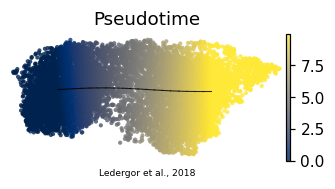

In [9]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
# map fitted curve nodes into the house orientation for edge overlay
xym = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
_,_,vt2 = np.linalg.svd(xym, full_matrices=False)
rot = np.arctan2(vt2[0,1], vt2[0,0]); Rm = np.array([[np.cos(-rot),-np.sin(-rot)],[np.sin(-rot),np.cos(-rot)]])
F = (sub.uns['graph']['F'].T - sub.obsm['X_umap'].mean(0)) @ Rm.T
flip = np.sign(np.corrcoef(plot.obsm['X_umap'][:,0], (xym@Rm.T)[:,0])[0,1])
F[:,0] *= flip
Bm = np.asarray(sub.uns['graph']['B'])
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ii,jj = np.where(np.triu(Bm>0))
for a,b in zip(ii,jj): ax.plot(F[[a,b],0], F[[a,b],1], '-', color='k', lw=.7, alpha=.8)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Ledergor et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')